# TP 3: Stabilise, then transform each token

In TP2 one attention head mixed the positions of a sequence. Here I build the two operations that act on each token alone. LayerNorm keeps every token at the same scale, the feed-forward network transforms it, and a residual addition keeps the input.

The diagram follows one token of C = 4 through these steps.

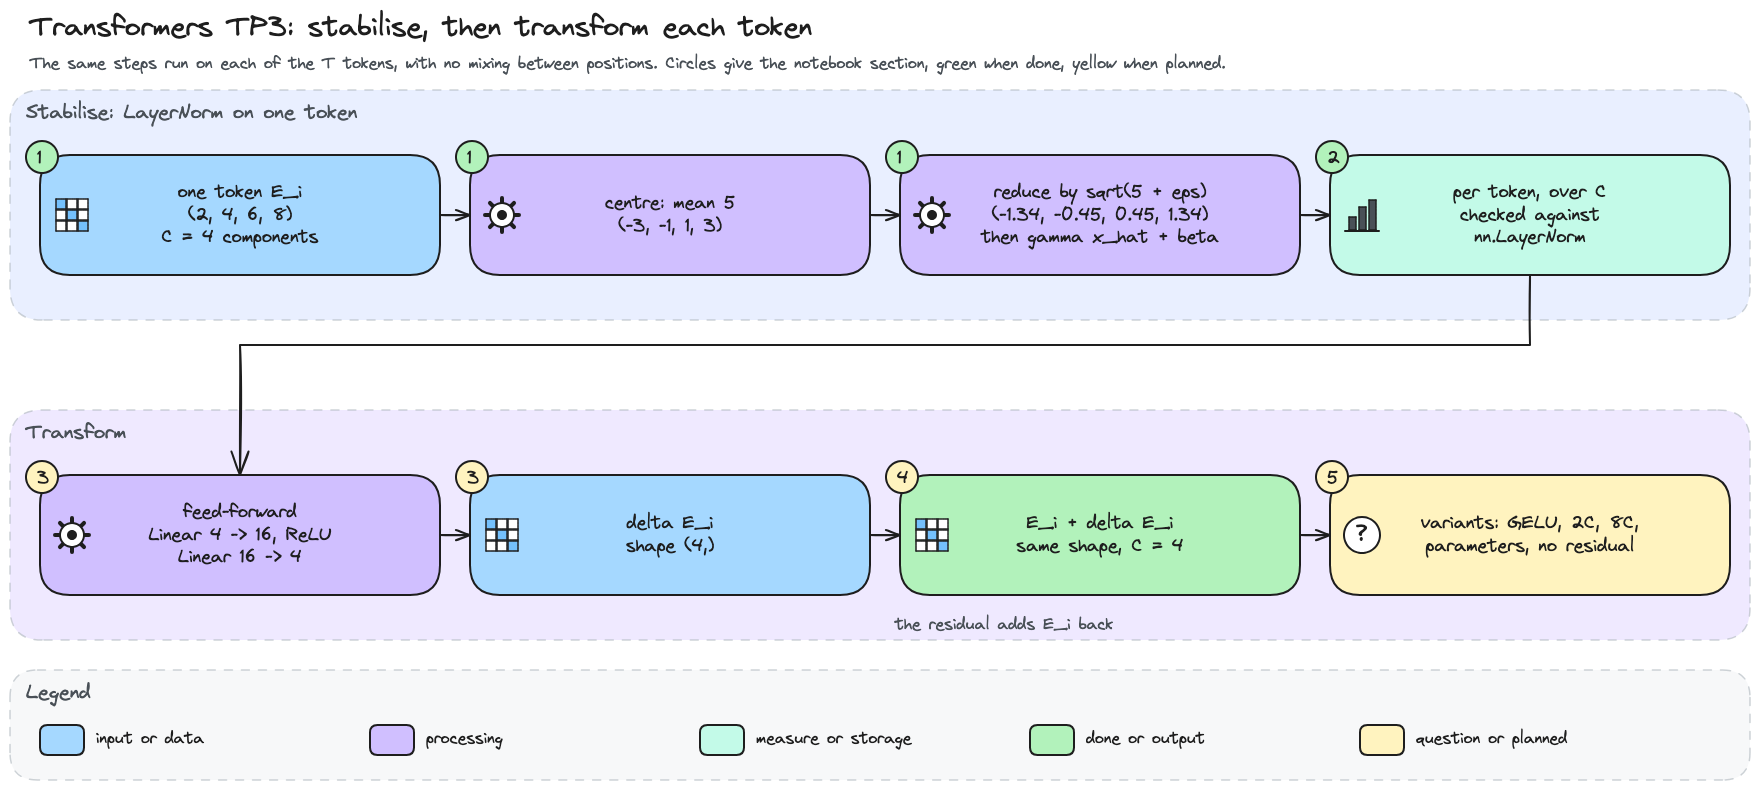

In [1]:
# Workflow diagram: one token through LayerNorm, the feed-forward network and the residual.
from IPython.display import Image, display

display(Image(filename='diagrams/transformers/tp3_workflow.png', width=900))

## 0. My problem and what I carry over

Section 6 of TP2 showed that the scale of the scores decides whether softmax stays informative. I want the same control over the scale of each token, then a small network that transforms each token on its own. The diagram links each lesson of TP2 to what it changes here.

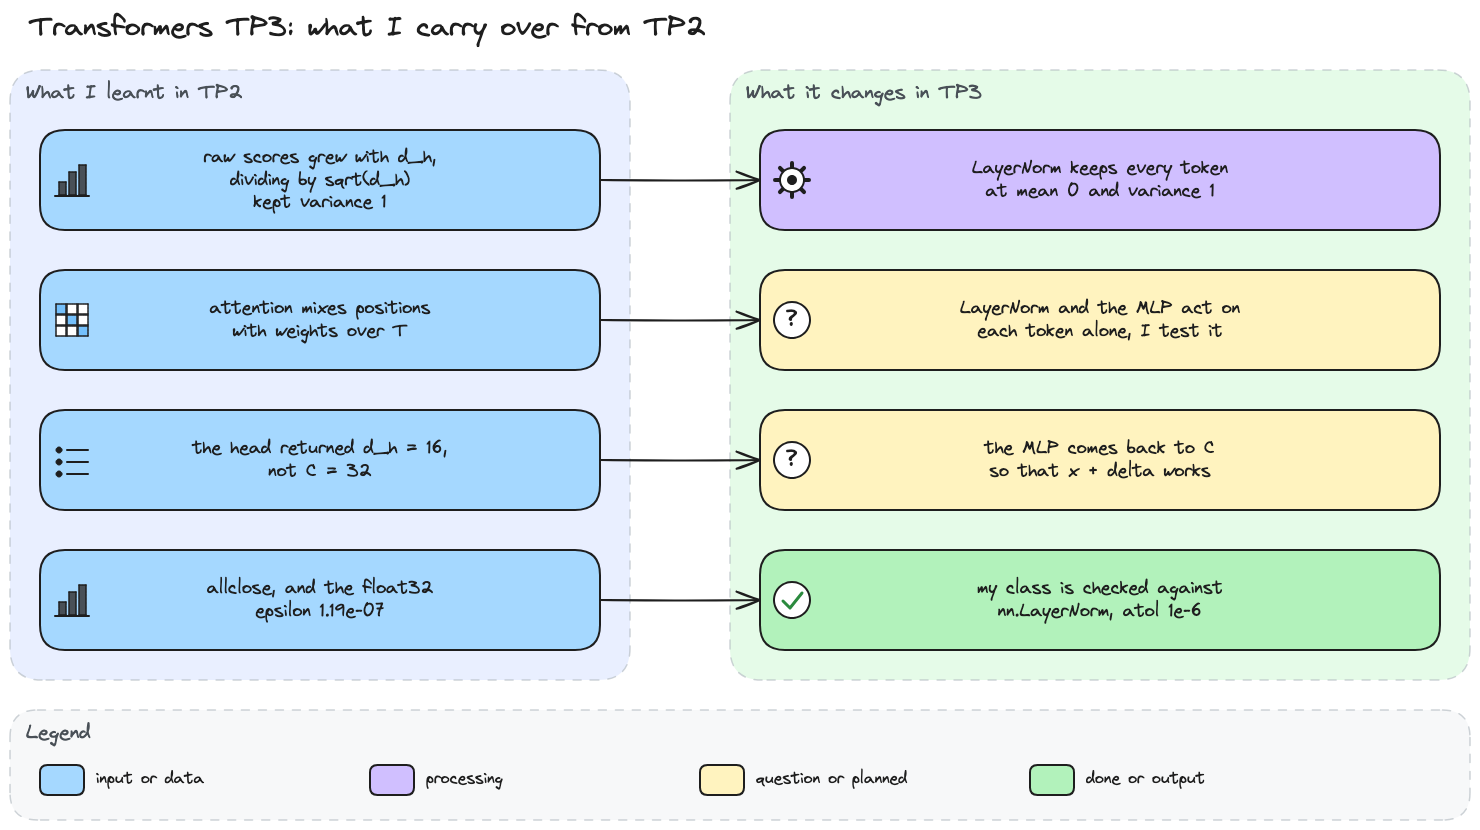

In [2]:
# What I carry over from TP2 (source in diagrams/transformers/).
display(Image(filename='diagrams/transformers/tp3_carry_over.png', width=900))

Before I start, I write down what I expect, so I can check it later.

> *My hypotheses:*
>
> - My LayerNorm gives every token a mean of 0 and a standard deviation of 1 over its C components, whatever its scale or shift. Section 1 checks it.
> - On a batch of 32 tokens, the features of one token come out near (0, 1), while one feature across the 32 tokens gets no imposed value. I test both lines in section 2.
> - About half of the ReLU activations are positive, because the first linear layer gives values centred on 0.
> - The feed-forward network acts on each token alone, so changing one token changes only its own output. Section 3 counts the activations and tests this.
> - In the pre-norm block, x_out stays close to x, because delta is small at initialisation. I measure it in section 4.
> - The parameters of the feed-forward network grow linearly with its expansion factor, and removing the residual keeps the shape (B, T, C). Section 5 counts and compares.

### My environment

I use the project's `.venv/bin/python` as kernel, with the same dependencies as in TP1 and TP2.

```sh
uv pip install --python .venv/bin/python -r requirements.txt
```

I keep every tensor on the CPU in this TP, because they are tiny and nothing is trained. I fix seed 42 once, and the handout cells also set their own seeds, so every random draw is the same at every run.

In [3]:
# Environment: versions, hardware and one seed for random and torch.
import platform
import random
import subprocess
import sys
from importlib.metadata import version

import torch

# Seed fixed once here, and the handout cells set their own seeds too.
RANDOM_STATE = 42
random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

# Versions and dependencies
print(f'Python: {platform.python_version()} ({sys.executable})')
for package in ('torch', 'matplotlib', 'ipykernel'):
    print(f'{package}: {version(package)}')

# System and processor
print(f'System: {platform.platform()}, {platform.machine()}')
if sys.platform == 'darwin':
    processor, ram = subprocess.check_output(
        ['sysctl', '-n', 'machdep.cpu.brand_string', 'hw.memsize'], text=True,
    ).splitlines()
    print(f'Processor: {processor}, RAM: {int(ram) / 2**30:g} GiB')

print(f'Device: CPU, seed: {RANDOM_STATE}')

Python: 3.14.7 (/Users/hopy/Documents/ING3_GIA/ING3_IA_GB_S1/NLP/.venv/bin/python)
torch: 2.14.0
matplotlib: 3.11.1
ipykernel: 7.3.0
System: macOS-26.5-arm64-arm-64bit-Mach-O, arm64
Processor: Apple M3 Max, RAM: 36 GiB
Device: CPU, seed: 42


## 1. Code LayerNorm

In TP2 I divided the scores by √d_h to keep their variance at 1. LayerNorm does a similar job on the activations, token by token, with a mean and a variance over the components of each token. I complete the class, then check what it removes and what ε, γ and β do.

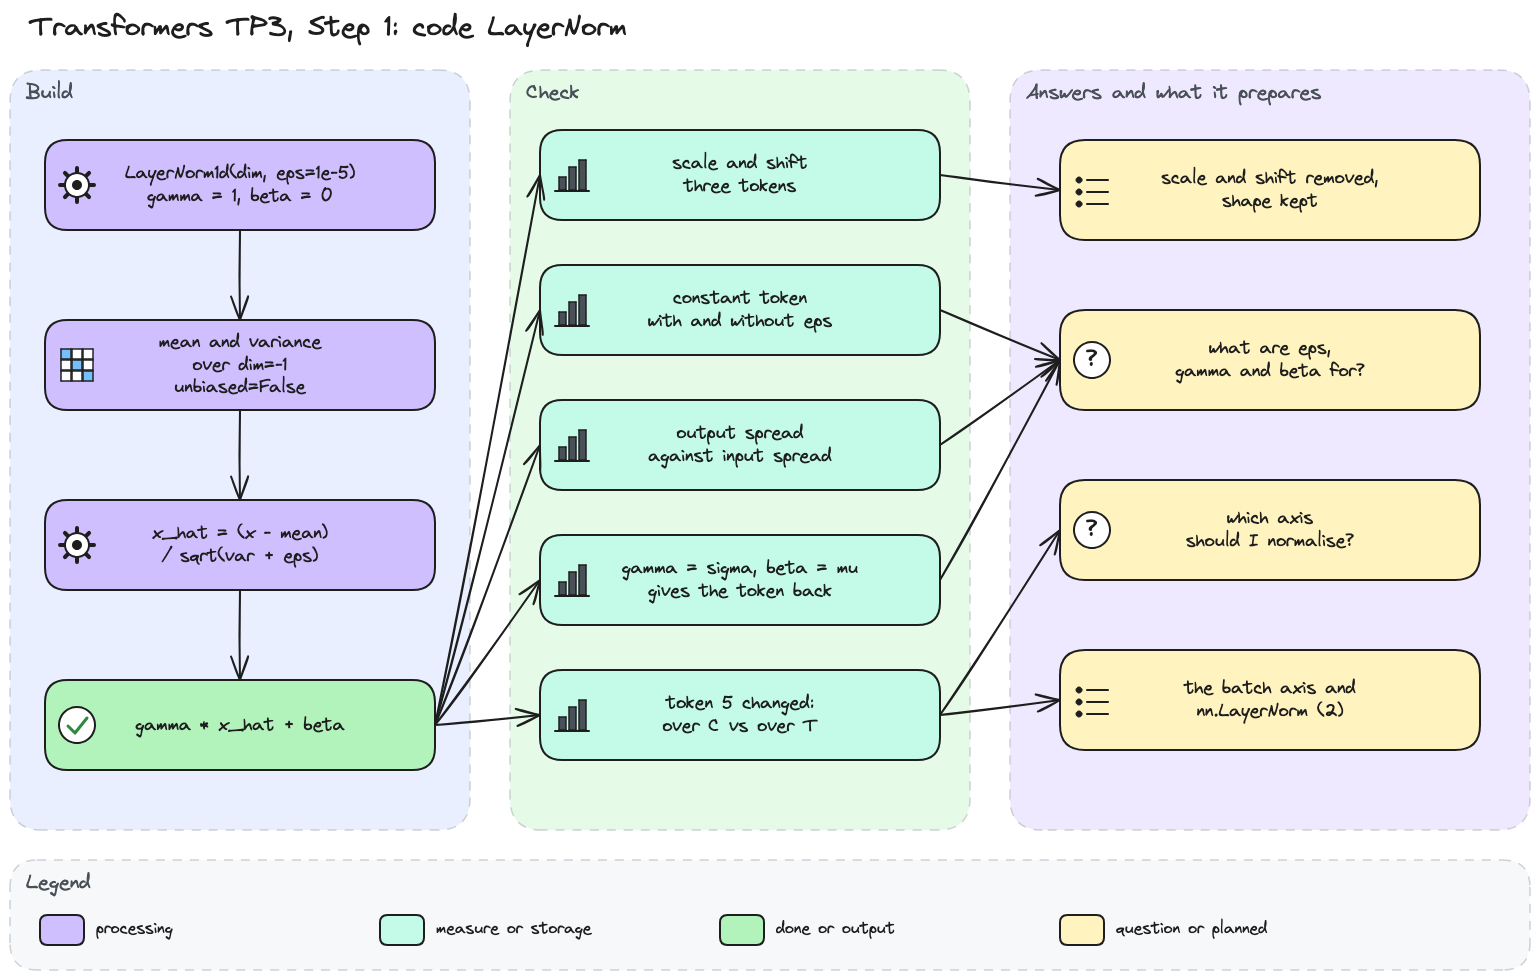

In [4]:
# Step 1 diagram: my LayerNorm, and the checks behind my answers.
display(Image(filename='diagrams/transformers/tp3_step1.png', width=900))

In [5]:
# My LayerNorm: mean and variance over the components of each token, then gamma and beta.
class LayerNorm1d:
    """Normalise each vector over its last dimension, then scale by gamma and shift by beta."""

    def __init__(self, dim, eps=1e-5):
        self.eps = eps
        self.gamma = torch.ones(dim)
        self.beta = torch.zeros(dim)

    def __call__(self, x):
        xmean = x.mean(dim=-1, keepdim=True)
        xvar = x.var(
            dim=-1, keepdim=True, unbiased=False
        )
        xhat = (x - xmean) / torch.sqrt(xvar + self.eps)
        return self.gamma * xhat + self.beta

I fill the two blanks. The statistics go over `dim=-1`, the C components of each token, because I want each token normalised without looking at the others. ε goes inside the square root, next to the variance. I start with tokens of C = 4 that I can check by hand.

Token (2, 4, 6, 8): mean 5, variance 5
[2.0, 4.0, 6.0, 8.0] -> [-1.34, -0.45, 0.45, 1.34]
[20.0, 40.0, 60.0, 80.0] -> [-1.34, -0.45, 0.45, 1.34]
[102.0, 104.0, 106.0, 108.0] -> [-1.34, -0.45, 0.45, 1.34]
Largest absolute mean of the outputs: 3.0e-08, std of each output: [1.0, 1.0, 1.0]


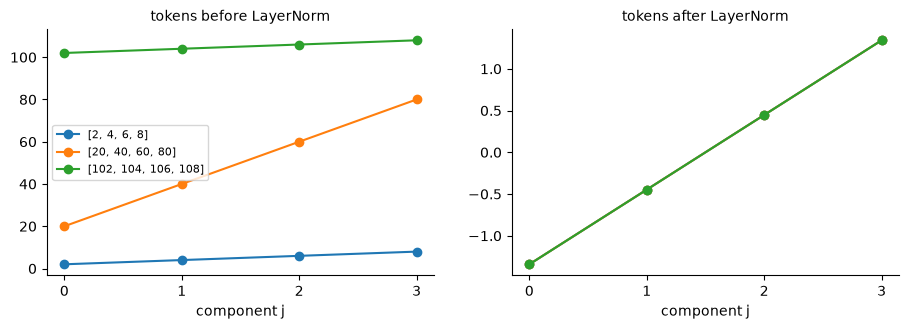

In [6]:
# What does LayerNorm remove? Three tokens of the same shape, at different scales and shifts.
import matplotlib.pyplot as plt

norm = LayerNorm1d(4)
tokens = torch.tensor([[2., 4., 6., 8.], [20., 40., 60., 80.], [102., 104., 106., 108.]])
first = tokens[0]
normed = norm(tokens)

print(f'Token (2, 4, 6, 8): mean {first.mean():.0f}, variance {first.var(unbiased=False):.0f}')
for token, row in zip(tokens.tolist(), normed.tolist()):
    print(f'{token} -> {[round(value, 2) for value in row]}')
print(f'Largest absolute mean of the outputs: {normed.mean(dim=-1).abs().max():.1e}, '
      f'std of each output: {[round(s, 3) for s in normed.std(dim=-1, unbiased=False).tolist()]}')

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for token, row in zip(tokens, normed):
    axes[0].plot(range(4), token, marker='o', label=str(token.int().tolist()))
    axes[1].plot(range(4), row, marker='o')
for ax, title in ((axes[0], 'tokens before LayerNorm'), (axes[1], 'tokens after LayerNorm')):
    ax.set_xticks(range(4))
    ax.set_xlabel('component j')
    ax.set_title(title, fontsize=10)
    ax.spines[['top', 'right']].set_visible(False)
axes[0].legend(fontsize=8)
plt.show()

Token (2, 4, 6, 8) has a mean of 5 and a variance of 5, so centring gives (−3, −1, 1, 3) and dividing by √5 gives (−1.34, −0.45, 0.45, 1.34). The token ten times larger and the token shifted by 100 give exactly the same output, and their three lines after LayerNorm lie on top of each other. Every output has a mean within 3.0e-08 of 0 and a std of 1.0, so my first hypothesis holds on these tokens.

LayerNorm keeps only how the components of a token compare with each other. Its scale and its offset are gone. A token whose components are all equal has nothing left to compare, and that is where ε comes in.

In [7]:
# Why eps? A constant token has a variance of 0, normalised with and without eps.
constant = torch.full((1, 4), 5.0)
print(f'Variance of (5, 5, 5, 5): {constant.var(unbiased=False).item()}')
print(f'With eps = 1e-5: {norm(constant).tolist()}')
print(f'With eps = 0: {LayerNorm1d(4, eps=0.0)(constant).tolist()}')

Variance of (5, 5, 5, 5): 0.0
With eps = 1e-5: [[0.0, 0.0, 0.0, 0.0]]
With eps = 0: [[nan, nan, nan, nan]]


The constant token has a variance of 0.0. With ε = 0 the formula divides 0 by 0 and returns NaN everywhere, and every later layer would receive NaN too. With ε = 1e-5 the division is by √ε, and the token becomes all zeros. So ε first keeps the division defined.

I wonder whether ε also changes tokens that are almost constant, so I vary their spread.

spread 0.0001: output std 0.032
spread 0.0003: output std 0.094
spread 0.001: output std 0.302
spread 0.003: output std 0.688
spread 0.01: output std 0.953
spread 0.03: output std 0.994
spread 0.1: output std 1.000
spread 1: output std 1.000
sqrt(eps) = 0.0032


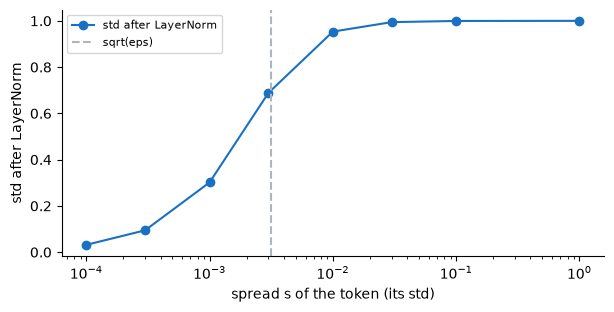

In [8]:
# How much does eps damp a token with a small spread? Output std of (-s, s, -s, s) against s.
import math

SPREADS = [1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1, 1.0]
output_stds = []
for s in SPREADS:
    output_stds.append(norm(torch.tensor([-s, s, -s, s])).std(unbiased=False).item())
    print(f'spread {s:g}: output std {output_stds[-1]:.3f}')
print(f'sqrt(eps) = {math.sqrt(norm.eps):.4f}')

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(SPREADS, output_stds, marker='o', color='#1971c2', label='std after LayerNorm')
ax.axvline(math.sqrt(norm.eps), linestyle='--', color='#adb5bd', label='sqrt(eps)')
ax.set_xscale('log')
ax.set_xlabel('spread s of the token (its std)')
ax.set_ylabel('std after LayerNorm')
ax.legend(fontsize=8)
ax.spines[['top', 'right']].set_visible(False)
plt.show()

Above a spread of 0.03 the output std stays at 0.994 or more, so ε has no visible effect there. Near √ε = 0.0032 it falls to 0.688, and at a spread of 0.0001 only 0.032 is left. The output std follows s / √(s² + ε), which gives 0.003 / √(9e-6 + 1e-5) = 0.688.

So ε keeps a nearly constant token small. Without it, LayerNorm would blow such a token, mostly rounding noise, up to a std of 1.

In [9]:
# What are gamma and beta for? Their starting values, then a choice that undoes the normalisation.
import torch.nn as nn

print(f'gamma: {norm.gamma.tolist()}, beta: {norm.beta.tolist()}')
print(f'Learned values for C = 4: {norm.gamma.numel() + norm.beta.numel()}, '
      f'nn.LayerNorm(4): {sum(p.numel() for p in nn.LayerNorm(4).parameters())}')

undo = LayerNorm1d(4)
undo.gamma = torch.sqrt(first.var(unbiased=False) + undo.eps).expand(4)  # the divisor itself
undo.beta = first.mean().expand(4)
print(f'gamma = sqrt(variance + eps), beta = mean: {undo(first).tolist()}, '
      f'largest gap {(undo(first) - first).abs().max().item():.1e}')

gamma: [1.0, 1.0, 1.0, 1.0], beta: [0.0, 0.0, 0.0, 0.0]
Learned values for C = 4: 8, nn.LayerNorm(4): 8
gamma = sqrt(variance + eps), beta = mean: [2.0, 4.0, 6.0, 8.0], largest gap 0.0e+00


γ starts at 1 and β at 0, so a fresh LayerNorm returns x̂ unchanged. There is one γ and one β per component, 8 learned values for C = 4, the same count as `nn.LayerNorm(4)`. When I set γ to the divisor √(5 + ε) and β to the mean 5, the token (2, 4, 6, 8) comes back with a gap of 0.0. So training can give each component a scale and an offset again, and even undo the normalisation if the next layer needs it.

The last open question of this step is the axis, so I try the other one.

over C, the components: largest change per row [0.0, 0.0, 0.0, 0.0, 0.0, 2.49, 0.0, 0.0]
over T, the positions: largest change per row [0.85, 0.53, 1.01, 0.68, 0.66, 2.17, 0.87, 0.61]


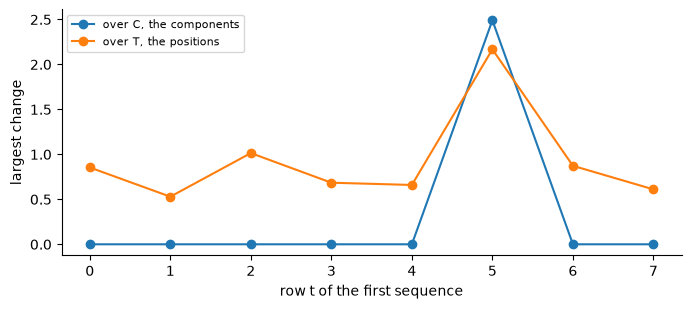

In [10]:
# Which axis? Token 5 of the first sequence replaced, then normalised over C and over T.
torch.manual_seed(1337)
B, T, C = 4, 8, 32
x = torch.randn(B, T, C)
changed = x.clone()
changed[0, 5] = torch.randn(C)

norm_c, norm_t = LayerNorm1d(C), LayerNorm1d(T)
versions = {'over C, the components': norm_c,
            # my class on the transposed tensor takes its statistics over the T positions
            'over T, the positions': lambda x: norm_t(x.transpose(1, 2)).transpose(1, 2)}
moves = {}
for name, normalise in versions.items():
    moves[name] = (normalise(changed) - normalise(x))[0].abs().max(dim=-1).values
    print(f'{name}: largest change per row {[round(v, 2) for v in moves[name].tolist()]}')

fig, ax = plt.subplots(figsize=(8, 3.2))
for name, move in moves.items():
    ax.plot(range(T), move, marker='o', label=name)
ax.set_xlabel('row t of the first sequence')
ax.set_ylabel('largest change')
ax.legend(fontsize=8)
ax.spines[['top', 'right']].set_visible(False)
plt.show()

I change only token 5 of the first sequence. Over C, only row 5 moves, by 2.49, and the other seven rows keep exactly their values. Over T, every row moves, from 0.53 to 1.01 outside row 5, and rows 0 to 4 change although they come before token 5.

Statistics over the positions would let a token see the future through the mean and the variance, which breaks the invariant I kept through TP2. So I normalise over the C components of each token, which keeps every token independent of the others.

> *My conclusion:*
>
> My completed `LayerNorm1d` takes the mean and the biased variance over the last dimension of each token. It removes the scale and the offset, so (2, 4, 6, 8), (20, 40, 60, 80) and (102, 104, 106, 108) all become (−1.34, −0.45, 0.45, 1.34). My hypothesis of a mean of 0 and a std of 1 per token holds.
>
> ε avoids a division by 0 and damps tokens whose spread is below √ε = 0.0032. γ and β then give each component a learned scale and offset. Section 2 looks at the batch axis and checks my class against `nn.LayerNorm`.
>
> My answers to the two questions of this step:
>
> 1. I normalise over the C components of each token, with `dim=-1`. Over the T positions, changing token 5 moved rows 0 to 4, so the past would see the future.
> 2. ε keeps the division defined, since a constant token gives NaN without it. γ and β, one of each per component and starting at 1 and 0, let training rescale and shift the normalised token, up to undoing the normalisation.

## 2. Choose the normalisation axis

Section 1 chose the components of each token as the axis. Here I take a batch of 32 tokens of 100 features and ask what my LayerNorm fixes on each token and what it leaves free on each feature. The diagram shows the handout cell and my checks around it.

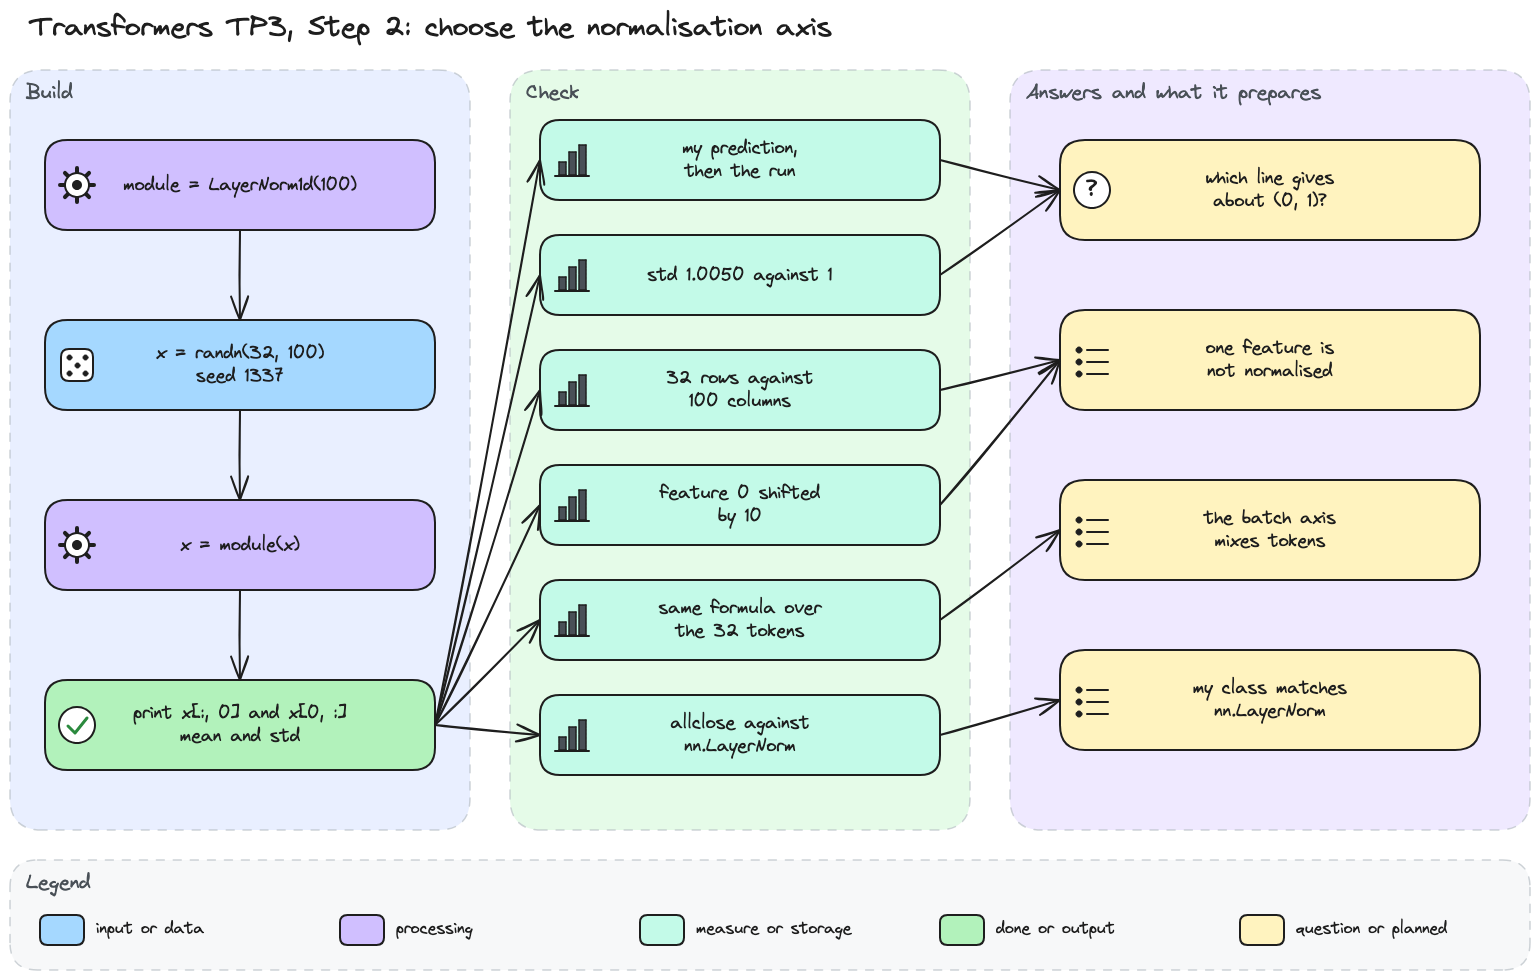

In [11]:
# Step 2 diagram: the handout cell, and the checks behind my answer.
display(Image(filename='diagrams/transformers/tp3_step2.png', width=900))

Before running the handout cell, I write my prediction. `x[0, :]` holds the 100 features of token 0, which my class normalises together, so it should give about (0, 1). `x[:, 0]` holds feature 0 across the 32 tokens, and no statistic of my class is taken over it, so I expect no fixed value.

In [12]:
# Which line gives about (0, 1)? The handout cell, run after writing my prediction.
torch.manual_seed(1337)
module = LayerNorm1d(100)

x = torch.randn(32, 100)
x = module(x)

print(x[:, 0].mean(), x[:, 0].std())
print(x[0, :].mean(), x[0, :].std())

tensor(0.1476) tensor(0.8847)
tensor(-2.3842e-09) tensor(1.0050)


My prediction holds. `x[0, :]` gives a mean of −2.4e-09 and a std of 1.0050, so token 0 sits at (0, 1) up to rounding. `x[:, 0]` gives 0.1476 and 0.8847, values that nothing in my class fixed.

A std of 1.0050 surprises me after a normalisation, so I want to explain it first.

In [13]:
# Why 1.0050 and not 1? The same std with the division by 100 that my LayerNorm uses.
print(f'x[0, :].std(unbiased=False): {x[0, :].std(unbiased=False):.4f}')
print(f'sqrt(100 / 99) = {math.sqrt(100 / 99):.4f}')

x[0, :].std(unbiased=False): 1.0000
sqrt(100 / 99) = 1.0050


With `unbiased=False`, token 0 has a std of exactly 1.0000. The handout calls `.std()`, which divides by 99 instead of 100, so it shows √(100/99) = 1.0050. My class divides by 100, as I chose in section 1, and I check later that `nn.LayerNorm` does the same.

One token and one feature are only two cases, so I look at all 32 tokens and all 100 features.

32 tokens, x[i, :]: means from -0.00 to 0.00, stds from 1.000 to 1.000
100 features, x[:, j]: means from -0.59 to 0.42, stds from 0.742 to 1.399


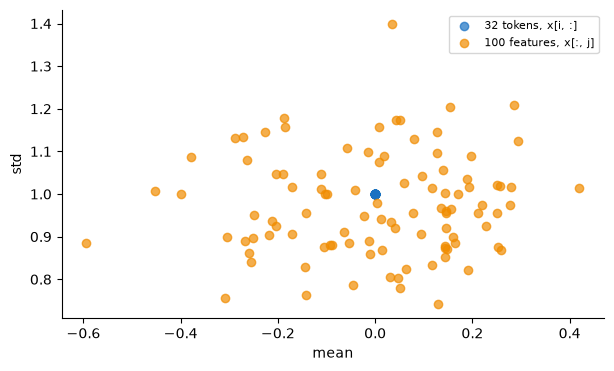

In [14]:
# What is fixed and what is free? Mean and std of the 32 tokens (rows) and the 100 features.
stats = {'32 tokens, x[i, :]': (x.mean(dim=1), x.std(dim=1, unbiased=False)),
         '100 features, x[:, j]': (x.mean(dim=0), x.std(dim=0, unbiased=False))}
for name, (means, stds) in stats.items():
    print(f'{name}: means from {means.min():.2f} to {means.max():.2f}, '
          f'stds from {stds.min():.3f} to {stds.max():.3f}')

fig, ax = plt.subplots(figsize=(7, 4))
for (name, (means, stds)), color in zip(stats.items(), ('#1971c2', '#f08c00')):
    ax.scatter(means, stds, color=color, alpha=0.7, label=name)
ax.set_xlabel('mean')
ax.set_ylabel('std')
ax.legend(fontsize=8)
ax.spines[['top', 'right']].set_visible(False)
plt.show()

Every one of the 32 tokens has a mean of 0.00 and a std of 1.000, and they all sit on a single point of the chart. The 100 features spread out, with means from −0.59 to 0.42 and stds from 0.742 to 1.399. The features stay roughly near (0, 1) only because the input came from `randn`.

I want to see what happens to a feature that is far from 0 in every token.

Same input as the handout cell: True
Feature 0: mean 0.15, std 0.87 without the shift, mean 7.08, std 0.44 with it
Feature 1: mean -0.59, std 0.89 without the shift, mean -0.49, std 0.64 with it
Tokens: largest absolute mean 2.9e-08, stds from 1.000 to 1.000


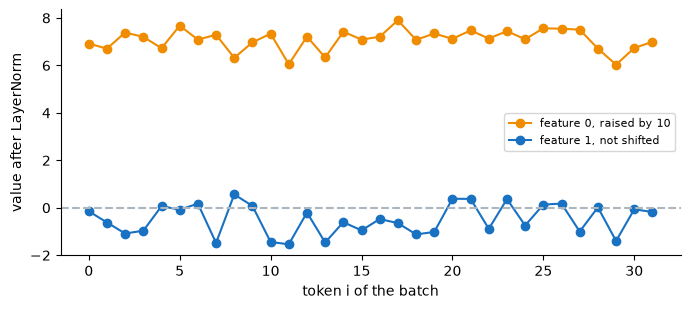

In [15]:
# Can a feature escape the normalisation? Feature 0 raised by 10 in every token, then LayerNorm.
torch.manual_seed(1337)
raw = torch.randn(32, 100)  # the handout input, before normalisation
print(f'Same input as the handout cell: {torch.equal(module(raw), x)}')

shifted = raw.clone()
shifted[:, 0] += 10
out = module(shifted)
for j in (0, 1):
    print(f'Feature {j}: mean {x[:, j].mean():.2f}, std {x[:, j].std(unbiased=False):.2f} '
          f'without the shift, mean {out[:, j].mean():.2f}, '
          f'std {out[:, j].std(unbiased=False):.2f} with it')
print(f'Tokens: largest absolute mean {out.mean(dim=1).abs().max():.1e}, stds from '
      f'{out.std(dim=1, unbiased=False).min():.3f} to {out.std(dim=1, unbiased=False).max():.3f}')

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(range(32), out[:, 0], marker='o', color='#f08c00', label='feature 0, raised by 10')
ax.plot(range(32), out[:, 1], marker='o', color='#1971c2', label='feature 1, not shifted')
ax.axhline(0, linestyle='--', color='#adb5bd')
ax.set_xlabel('token i of the batch')
ax.set_ylabel('value after LayerNorm')
ax.legend(fontsize=8)
ax.spines[['top', 'right']].set_visible(False)
plt.show()

Raising feature 0 by 10 in every token moves its normalised mean from 0.15 to 7.08, and its std falls from 0.87 to 0.44. LayerNorm leaves this feature large in every token, so nothing is imposed along the batch.

Feature 1, which I did not touch, also moves, from a mean of −0.59 to −0.49 and from a std of 0.89 to 0.64. The shift raised the mean of every token by 10/100 = 0.1 and widened its spread, so every other feature of a token is rescaled too. The tokens themselves stay at a mean within 2.9e-08 of 0 and a std of 1.000.

over the features, LayerNorm: token 0 moves by 0.00, tokens other than 5 by up to 0.00
over the 32 tokens of the batch: token 0 moves by 0.27, tokens other than 5 by up to 0.43
One token alone, over the batch: largest value 0.0
One token alone, LayerNorm: same output as in the batch True


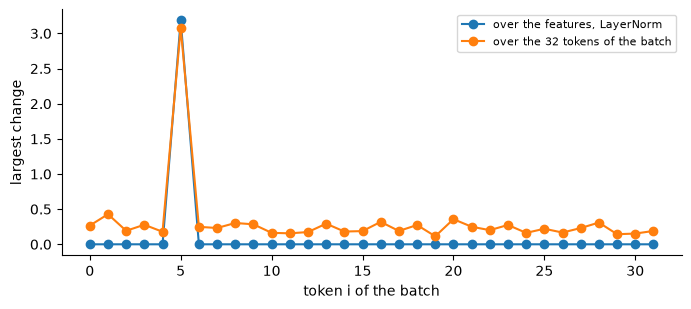

In [16]:
# What if the statistics went over the batch? Token 5 replaced, then both axes on the 32 tokens.
changed = raw.clone()
changed[5] = torch.randn(100)
norm_batch = LayerNorm1d(32)
batch_versions = {'over the features, LayerNorm': module,
                  # my class on the transposed tensor takes its statistics over the 32 tokens
                  'over the 32 tokens of the batch': lambda x: norm_batch(x.T).T}
moves = {}
for name, normalise in batch_versions.items():
    moves[name] = (normalise(changed) - normalise(raw)).abs().max(dim=1).values
    others = torch.cat([moves[name][:5], moves[name][6:]])
    print(f'{name}: token 0 moves by {moves[name][0]:.2f}, '
          f'tokens other than 5 by up to {others.max():.2f}')

alone = raw[:1]
print(f'One token alone, over the batch: largest value {LayerNorm1d(1)(alone.T).T.abs().max():.1f}')
print(f'One token alone, LayerNorm: same output as in the batch '
      f'{torch.allclose(module(alone), module(raw)[:1])}')

fig, ax = plt.subplots(figsize=(8, 3.2))
for name, move in moves.items():
    ax.plot(range(32), move, marker='o', label=name)
ax.set_xlabel('token i of the batch')
ax.set_ylabel('largest change')
ax.legend(fontsize=8)
ax.spines[['top', 'right']].set_visible(False)
plt.show()

With LayerNorm, replacing token 5 changes no other token, with 0.00 everywhere outside token 5. With the same formula over the 32 tokens, token 0 moves by 0.27 and the other tokens by up to 0.43. Each of them now depends on the mean and the variance of the whole batch. A token alone in its batch collapses to 0.0 on that axis, while LayerNorm gives it the same output as inside the batch.

A batch holds unrelated sequences, so the output of one sequence should not depend on the others. The feature axis gives that, and it still works when I generate a single sequence, as in TP1 transformers.

In [17]:
# Does my class match nn.LayerNorm? The handout check, then the largest gap on three inputs.
print(torch.allclose(module(x), nn.LayerNorm(100)(x), atol=1e-6))

reference = nn.LayerNorm(100)
for name, inputs in (('handout x, already normalised', x), ('raw input', raw),
                     ('raw * 50 + 7', raw * 50 + 7)):
    print(f'{name}: largest gap {(module(inputs) - reference(inputs)).abs().max():.1e}')
print(f'float32 epsilon: {torch.finfo(torch.float32).eps:.2e}')

True
handout x, already normalised: largest gap 4.8e-07
raw input: largest gap 4.8e-07
raw * 50 + 7: largest gap 4.8e-07
float32 epsilon: 1.19e-07


The handout check prints True. The largest gap is 4.8e-07 on the handout `x`, on the raw input and on raw × 50 + 7, about four times the float32 epsilon of 1.19e-07. That is rounding, well under the tolerance of 1e-6. The handout `x` was already normalised, so I am glad the check also holds on raw inputs at a larger scale.

My class starts with γ = 1 and β = 0, which hides any mistake in them, so I test random values next.

In [18]:
# Do gamma, beta and the variance match too? Random gamma and beta in both, then Bessel's variance.
torch.manual_seed(RANDOM_STATE)
with torch.no_grad():
    reference.weight.normal_()
    reference.bias.normal_()
mine = LayerNorm1d(100)
mine.gamma, mine.beta = reference.weight.detach().clone(), reference.bias.detach().clone()
print(f'Random gamma and beta in both: largest gap {(mine(raw) - reference(raw)).abs().max():.1e}, '
      f'allclose {torch.allclose(mine(raw), reference(raw), atol=1e-6)}, '
      f'largest |gamma| {mine.gamma.abs().max():.2f}')

unbiased = (raw - raw.mean(-1, keepdim=True)) / torch.sqrt(raw.var(-1, keepdim=True) + mine.eps)
print(f'Variance divided by 99 instead of 100: largest gap '
      f'{(unbiased - nn.LayerNorm(100)(raw)).abs().max():.3f}')

Random gamma and beta in both: largest gap 1.4e-06, allclose True, largest |gamma| 2.22
Variance divided by 99 instead of 100: largest gap 0.017


With random γ and β copied into both versions, the largest gap grows to 1.4e-06, since a γ of up to 2.22 multiplies the rounding error. `allclose` still returns True, because it also allows a gap relative to the size of the values. With the variance divided by 99, the gap jumps to 0.017, far above any rounding. So `nn.LayerNorm` uses the biased variance, like my class with `unbiased=False`.

> *My conclusion:*
>
> LayerNorm fixes each token at mean 0 and std 1 over its features and leaves every feature free across the batch. All 32 tokens reach (0, 1), while the features keep means from −0.59 to 0.42, and a feature raised by 10 stays near 7.08. My hypothesis on the two lines of the handout holds.
>
> Statistics over the batch would make each token depend on the others, and a token alone would collapse to 0. My class matches `nn.LayerNorm` within 4.8e-07 with the same biased variance, so section 3 can build on it.
>
> My answer to the question of this step:
>
> - I predicted `x[0, :]`, the 100 features of token 0. It gives a mean of −2.4e-09 and a std of 1.0050, or 1.0000 with the division by 100, while `x[:, 0]` gives 0.1476 and 0.8847.

## 3. Build the feed-forward network

I will build the network C → 4C → C with a ReLU in the middle and apply it to 32 tokens of 100 components. I want to know what share of the hidden activations is positive, and why the output comes back to C.

## 4. Add the residual connection

I will chain LayerNorm and the feed-forward network in the pre-norm order, then add the result to the input. The shapes of `x`, `delta` and `x_out` should show why the network has to come back to C.

## 5. Test variants

I will swap ReLU for GELU, try an expansion of 2C and of 8C, and count the parameters in each case. Then I remove the residual addition and compare what changes.

## Summary

I will answer three questions from my measurements. Which dimension does LayerNorm keep, does the MLP mix tokens, and what is the residual connection for?